21st October:
Step 1: Downloading our data into Python

In [1]:
import pandas as pd  

In [2]:
df = pd.read_csv(r"C:\Users\grace\Documents\Galway University\Final Year\Machine Learning Project\Data\online_shoppers_intention.csv")

In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Step 2: Completing our Data Audit

In [6]:
df.shape

(12330, 18)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [10]:
df.isna().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [11]:
df.duplicated().sum()

125

In [12]:
df[df.duplicated(keep = False)].head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


In [13]:
df[df.duplicated(keep = False)]["Revenue"].value_counts()

False    201
Name: Revenue, dtype: int64

In [14]:
df["Revenue"].value_counts()

False    10422
True      1908
Name: Revenue, dtype: int64

In [15]:
df["Revenue"].value_counts(normalize=True)*100

False    84.525547
True     15.474453
Name: Revenue, dtype: float64

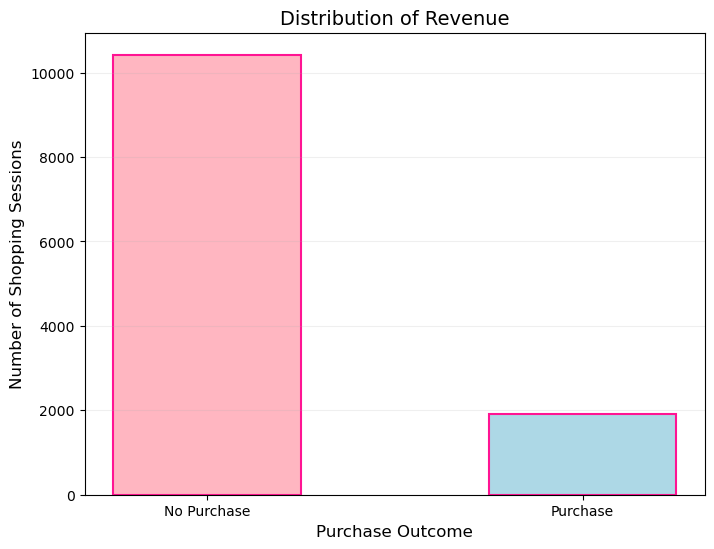

In [30]:
import matplotlib.pyplot as plt

revenue_counts = df["Revenue"].value_counts()

plt.figure(figsize=(8, 6))

plt.bar(
    ["No Purchase", "Purchase"],
    [revenue_counts[False], revenue_counts[True]],
    color=["lightpink", "lightblue"],
    edgecolor="deeppink",
    linewidth=1.5,
    width=0.5
)

plt.title("Distribution of Revenue", fontsize=14)
plt.xlabel("Purchase Outcome", fontsize=12)
plt.ylabel("Number of Shopping Sessions", fontsize=12)

plt.grid(axis="y", alpha=0.2)
plt.show()

In [17]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [18]:
import matplotlib.pyplot as plt

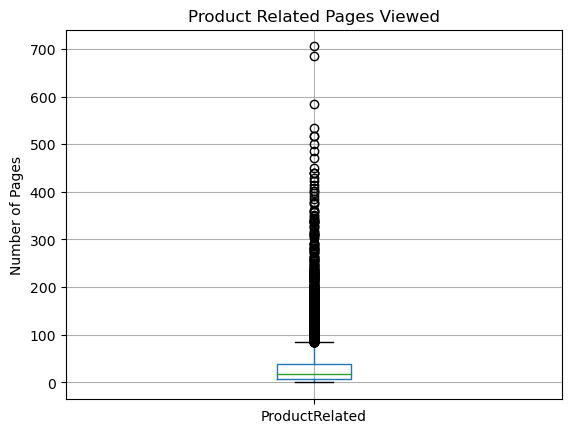

In [20]:
df.boxplot(column = "ProductRelated")
plt.title("Product Related Pages Viewed")
plt.ylabel("Number of Pages")
plt.show()

The above box plot is not very clear, quite difficult to read and identify outliers so I will redo a larger boxplot that used brighter colours for the points in an attempt to make it easier to read

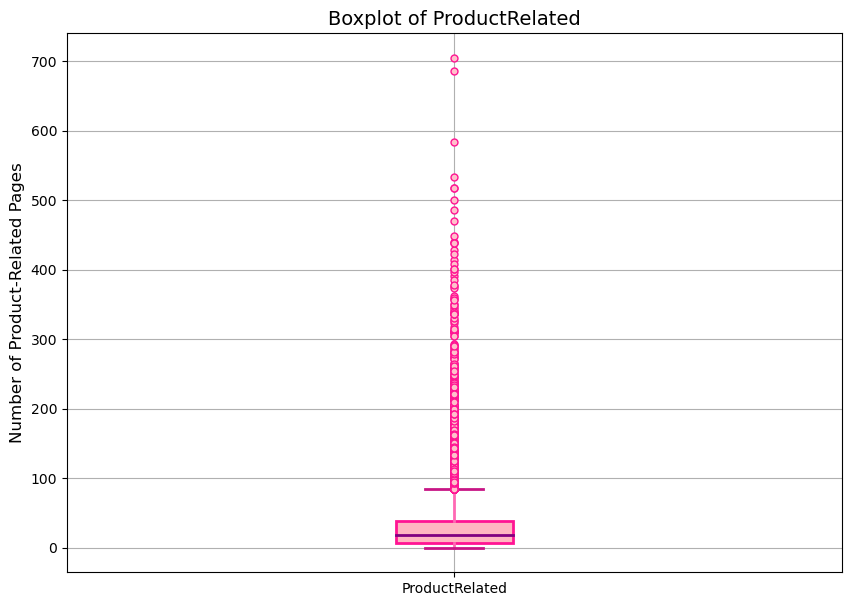

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

df.boxplot(
    column="ProductRelated",
    patch_artist=True,
    boxprops=dict(facecolor="lightpink", color="deeppink", linewidth=2),
    whiskerprops=dict(color="hotpink", linewidth=2),
    capprops=dict(color="mediumvioletred", linewidth=2),
    medianprops=dict(color="purple", linewidth=2),
    flierprops=dict(marker='o', markerfacecolor="pink", markeredgecolor="deeppink", markersize=5)
)

plt.title("Boxplot of ProductRelated", fontsize=14)
plt.ylabel("Number of Product-Related Pages", fontsize=12)
plt.show()

This boxplot is clearer and more visually appealing. From the above boxplot we can see that there are many potential outliers with the most extreme observation involving just over 700 product related visits.
The distribution is right-skewed.
I will also display this in a histogram

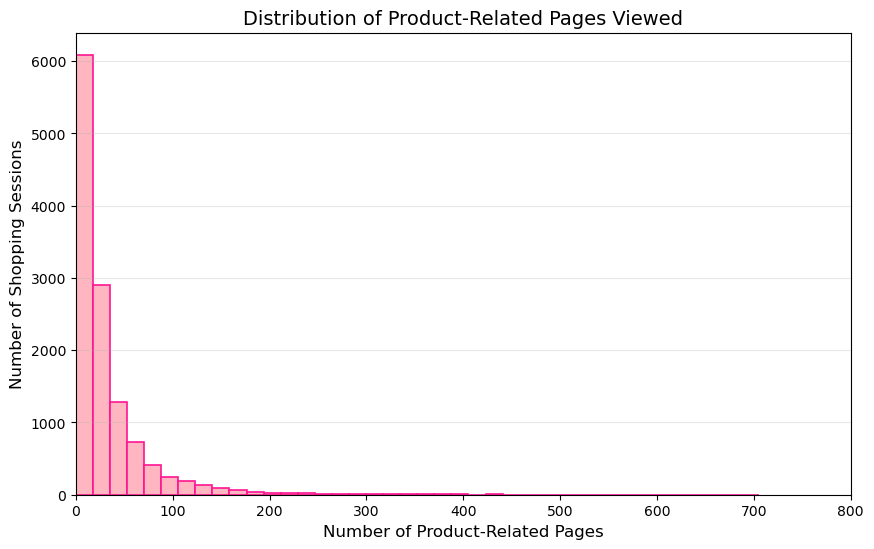

In [25]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["ProductRelated"],
    bins=40,
    color="lightpink",
    edgecolor="deeppink",
    linewidth=1.2
)

plt.title("Distribution of Product-Related Pages Viewed", fontsize=14)
plt.xlabel("Number of Product-Related Pages", fontsize=12)
plt.ylabel("Number of Shopping Sessions", fontsize=12)

plt.grid(axis="y", alpha=0.3)
plt.xlim(0,800)
plt.show()

The histogram above indicates that majority of shopping sessions involve very few product pages. The data is heavily right skewed. As the number of product pages increases, the number of shopping sessions decreases resulting in a long tail extending to the right. A small number or sessions contain hundreds of product page visits, with the maximum being 705.

At this time, we cannot conclude that these are errors.